# U-Net sur ISBI 2012 (EM Segmentation Challenge)
Implémentation PyTorch de l'article [arXiv:1505.04597](https://arxiv.org/abs/1505.04597) sur son dataset principal :
30 coupes de microscopie électronique (512×512) du cordon nerveux d'une larve de drosophile.

**Ce que le notebook reproduit de l'article**
- U-Net à convolutions *valid* : entrée 572×572 → sortie 388×388
- stratégie **overlap-tile** (miroir sur les bords) pour segmenter une image entière
- **déformations élastiques** (grille 3×3, écart-type 10 px) + rotations/flips
- **carte de poids** : équilibrage des classes + bonus aux fines frontières entre cellules qui se touchent (w0=10, σ=5)
- SGD, momentum 0.99, batch de 1 image, init He

## 1. Imports et données

In [1]:
import os, glob, zipfile, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", device)

device : cuda


In [2]:
DATA_DIR = "data"; os.makedirs(DATA_DIR, exist_ok=True)

def find(name):
    hits = [p for p in glob.glob(f"{DATA_DIR}/**/*.tif*", recursive=True) if name in os.path.basename(p).lower()]
    return hits[0] if hits else None

if not (find("train-volume") and find("train-labels")):
    url = "https://downloads.imagej.net/ISBI-2012-challenge.zip"
    try:
        zpath = os.path.join(DATA_DIR, "isbi.zip")
        urllib.request.urlretrieve(url, zpath)
        zipfile.ZipFile(zpath).extractall(DATA_DIR)
    except Exception as e:
        print("Téléchargement impossible :", e)

IMG_PATH, LAB_PATH = find("train-volume"), find("train-labels")
print(IMG_PATH, LAB_PATH)
assert IMG_PATH and LAB_PATH, "Placez train-volume.tif et train-labels.tif dans ./data"

data/train-volume.tif data/train-labels.tif


In [3]:
def read_tif(path):
    im = Image.open(path)
    frames = []
    for i in range(im.n_frames):
        im.seek(i); frames.append(np.array(im))
    return np.stack(frames)

images = read_tif(IMG_PATH).astype(np.float32) / 255.0      # (30, 512, 512)
labels = (read_tif(LAB_PATH) > 127).astype(np.uint8)         # 1 = cellule, 0 = membrane
print(images.shape, labels.shape, "| part de cellules :", labels.mean().round(3))

(30, 512, 512) (30, 512, 512) | part de cellules : 0.78


## 2. Prétraitement : carte de poids et déformations élastiques
- **Carte de poids** `w(x) = w_c(x) + w0 · exp(-(d1+d2)² / 2σ²)` où `d1`, `d2` sont les distances aux deux cellules les plus proches. Elle force le réseau à bien séparer les cellules adjacentes.
- **Déformation élastique** : déplacements aléatoires sur une grille 3×3, interpolés (cubique) à toute l'image.

In [4]:
def weight_map(lab, w0=10.0, sigma=5.0):
    freq = lab.mean()
    wc = np.where(lab == 1, 0.5 / freq, 0.5 / (1 - freq)).astype(np.float32)  # équilibrage des classes
    cells, n = ndi.label(lab)                                                    # cellules = composantes connexes
    if n < 2: return wc
    d1 = np.full(lab.shape, np.inf, np.float32); d2 = d1.copy()
    for k in range(1, n + 1):                                                    # 2 plus petites distances
        d = ndi.distance_transform_edt(cells != k).astype(np.float32)
        m = d < d1
        d2 = np.where(m, d1, np.minimum(d2, d)); d1 = np.where(m, d, d1)
    return wc + w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))

def elastic_deform(img, lab, wm, rng, grid=3, std=10.0):
    h, w = img.shape
    disp = rng.normal(0, std, (2, grid, grid))
    disp = np.stack([ndi.zoom(d, (h / grid, w / grid), order=3) for d in disp])
    yy, xx = np.mgrid[:h, :w]
    coords = [yy + disp[0], xx + disp[1]]
    f = lambda a, o: ndi.map_coordinates(a, coords, order=o, mode="reflect")
    return f(img, 3), f(lab, 0), f(wm, 1)

cartes de poids calculées en 41s


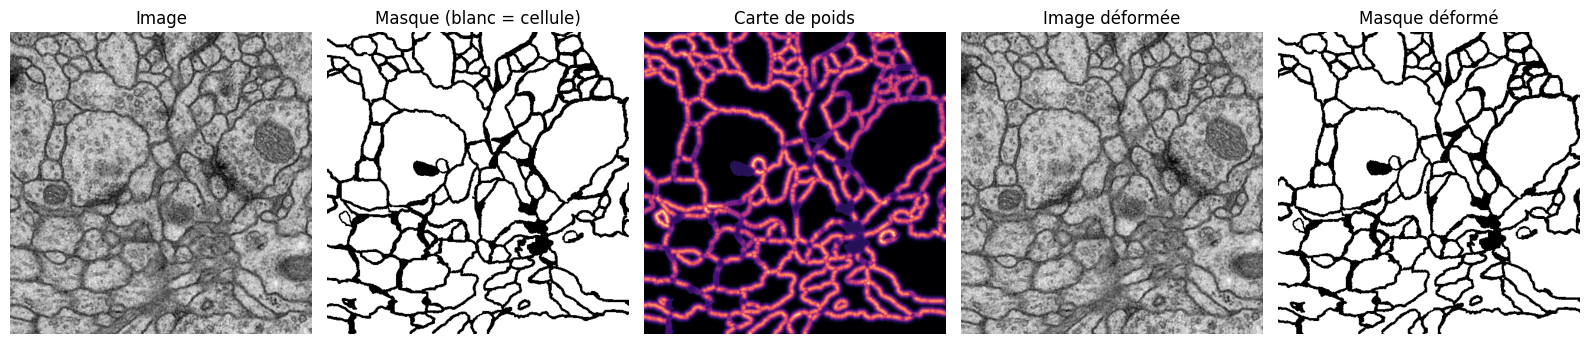

In [5]:
import time; t = time.time()
wmaps = np.stack([weight_map(l) for l in labels]).astype(np.float32)
print(f"cartes de poids calculées en {time.time()-t:.0f}s")

# Découpage : 25 coupes pour l'entraînement, 5 pour la validation
N_TRAIN = 25
tr_img, tr_lab, tr_w = images[:N_TRAIN], labels[:N_TRAIN], wmaps[:N_TRAIN]
va_img, va_lab = images[N_TRAIN:], labels[N_TRAIN:]
MEAN, STD = tr_img.mean(), tr_img.std()

# Aperçu des données, de la carte de poids et d'une déformation élastique
rng = np.random.default_rng(1)
ei, el, ew = elastic_deform(tr_img[0], tr_lab[0], tr_w[0], rng)
fig, ax = plt.subplots(1, 5, figsize=(16, 3.4))
for a, im, t_ in zip(ax, [tr_img[0], tr_lab[0], tr_w[0], ei, el],
                     ["Image", "Masque (blanc = cellule)", "Carte de poids", "Image déformée", "Masque déformé"]):
    a.imshow(im, cmap="gray" if t_ != "Carte de poids" else "magma"); a.set_title(t_); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Le modèle
Convolutions 3×3 *valid* (`padding=0`) : l'image rétrécit, donc on **rogne** les skip connections avant de les concaténer. Entrée 572×572 → sortie 388×388.

In [6]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(cin, cout, 3), nn.ReLU(inplace=True),
                                 nn.Conv2d(cout, cout, 3), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

def center_crop(t, target):
    th, tw = target.shape[-2:]; h, w = t.shape[-2:]
    i, j = (h - th) // 2, (w - tw) // 2
    return t[..., i:i+th, j:j+tw]

class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=2, base=64):
        super().__init__()
        chs = [base * 2**i for i in range(5)]                     # 64,128,256,512,1024
        self.downs = nn.ModuleList(); c = in_ch
        for ch in chs[:-1]:
            self.downs.append(DoubleConv(c, ch)); c = ch
        self.pool = nn.MaxPool2d(2)
        self.bottom = DoubleConv(chs[-2], chs[-1])
        self.ups, self.up_convs = nn.ModuleList(), nn.ModuleList()
        for ch in reversed(chs[:-1]):
            self.ups.append(nn.ConvTranspose2d(ch * 2, ch, 2, stride=2))
            self.up_convs.append(DoubleConv(ch * 2, ch))
        self.out = nn.Conv2d(base, n_classes, 1)
        for m in self.modules():                                  # init He, comme dans l'article
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x); skips.append(x); x = self.pool(x)
        x = self.bottom(x)
        for up, conv, skip in zip(self.ups, self.up_convs, reversed(skips)):
            x = up(x)
            x = conv(torch.cat([center_crop(skip, x), x], dim=1))
        return self.out(x)

with torch.no_grad():
    print(UNet(base=8)(torch.randn(1, 1, 572, 572)).shape)       # attendu : [1, 2, 388, 388]

torch.Size([1, 2, 388, 388])


## 4. Dataset d'entraînement (overlap-tile)
L'image (512×512) est déformée, tournée/retournée, puis **complétée par miroir de 92 px** sur chaque bord. On y découpe une tuile d'entrée 572×572 ; la cible est la zone centrale 388×388 (poids correspondants inclus).

In [7]:
IN, OUT = 572, 388
PAD = (IN - OUT) // 2        # 92
SIZE = 512

class EMTrain(Dataset):
    def __init__(self, imgs, labs, wms, n_samples):
        self.imgs, self.labs, self.wms, self.n = imgs, labs, wms, n_samples
        self.rng = np.random.default_rng(0)
    def __len__(self): return self.n
    def __getitem__(self, _):
        r = self.rng; k = r.integers(len(self.imgs))
        img, lab, wm = elastic_deform(self.imgs[k], self.labs[k], self.wms[k], r)
        rot = r.integers(4); img, lab, wm = [np.rot90(a, rot) for a in (img, lab, wm)]
        if r.random() < .5: img, lab, wm = [a[:, ::-1] for a in (img, lab, wm)]
        img = np.pad((img - MEAN) / STD, PAD, mode="reflect")
        i, j = r.integers(0, SIZE - OUT + 1, 2)
        x = img[i:i+IN, j:j+IN]; y = lab[i:i+OUT, j:j+OUT]; w = wm[i:i+OUT, j:j+OUT]
        return (torch.from_numpy(x.astype(np.float32).copy())[None],
                torch.from_numpy(y.astype(np.int64).copy()),
                torch.from_numpy(w.astype(np.float32).copy()))

# Config selon le matériel (l'architecture est identique, seule la largeur change)
if device == "cuda": BASE, EPOCHS = 64, 20     # modèle complet de l'article
else:                BASE, EPOCHS = 16, 3      # version allégée pour CPU
STEPS = 100                                     # images vues par époque
train_dl = DataLoader(EMTrain(tr_img, tr_lab, tr_w, STEPS), batch_size=1)
print("BASE =", BASE, "| EPOCHS =", EPOCHS)

BASE = 64 | EPOCHS = 20


## 5. Prédiction d'une image entière (overlap-tile) et métriques
Une image 512×512 est couverte par 4 tuiles de sortie 388×388 (départs en 0 et 124), chacune calculée depuis une entrée 572×572 prise sur l'image complétée par miroir.

In [8]:
@torch.no_grad()
def predict_full(model, img):
    model.eval()
    p = np.pad((img - MEAN) / STD, PAD, mode="reflect")
    prob = np.zeros((SIZE, SIZE), np.float32)
    starts = [0, SIZE - OUT]
    for i in starts:
        for j in starts:
            x = torch.from_numpy(p[i:i+IN, j:j+IN].astype(np.float32))[None, None].to(device)
            prob[i:i+OUT, j:j+OUT] = F.softmax(model(x), 1)[0, 1].cpu().numpy()   # P(cellule)
    return prob

def metrics(prob, lab):
    pred = prob > 0.5
    inter = (pred & (lab == 1)).sum()
    dice = 2 * inter / (pred.sum() + (lab == 1).sum() + 1e-9)
    iou = inter / ((pred | (lab == 1)).sum() + 1e-9)
    return dict(pixel_acc=(pred == lab).mean(), dice=dice, iou=iou)

def evaluate(model):
    ms = [metrics(predict_full(model, i), l) for i, l in zip(va_img, va_lab)]
    return {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}

## 6. Entraînement
Perte : cross-entropy **pondérée par la carte de poids**. SGD, lr 0.01, momentum 0.99, batch 1 (comme dans l'article).

In [9]:
model = UNet(in_ch=1, n_classes=2, base=BASE).to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.99)

history = []
for epoch in range(EPOCHS):
    model.train(); tot = 0
    for x, y, w in train_dl:
        x, y, w = x.to(device), y.to(device), w.to(device)
        loss = (F.cross_entropy(model(x), y, reduction="none") * w).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item()
    m = evaluate(model); history.append((tot / STEPS, m["dice"]))
    print(f"epoch {epoch+1:2d}/{EPOCHS} | loss={tot/STEPS:.4f} | val: acc={m['pixel_acc']:.3f} dice={m['dice']:.3f} iou={m['iou']:.3f}")

epoch  1/20 | loss=1.4649 | val: acc=0.831 dice=0.891 iou=0.803
epoch  2/20 | loss=1.5563 | val: acc=0.781 dice=0.865 iou=0.762
epoch  3/20 | loss=1.6419 | val: acc=0.683 dice=0.756 iou=0.608
epoch  4/20 | loss=1.5768 | val: acc=0.201 dice=0.004 iou=0.002
epoch  5/20 | loss=2.0653 | val: acc=0.199 dice=0.000 iou=0.000
epoch  6/20 | loss=1.9124 | val: acc=0.801 dice=0.889 iou=0.801
epoch  7/20 | loss=1.8573 | val: acc=0.801 dice=0.889 iou=0.801
epoch  8/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch  9/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 10/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 11/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 12/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 13/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 14/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 15/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epoch 16/20 | loss=nan | val: acc=0.199 dice=0.000 iou=0.000
epo

## 7. Les Résultats

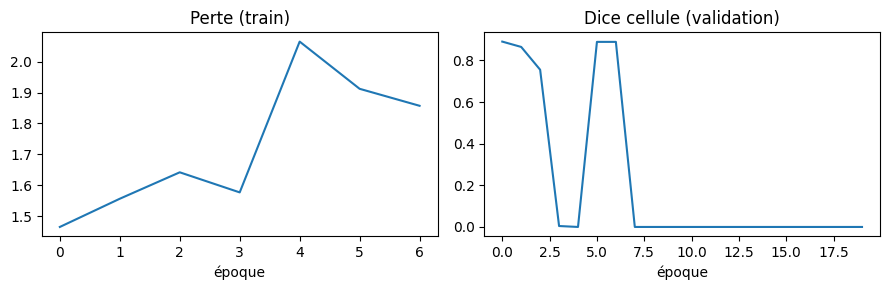

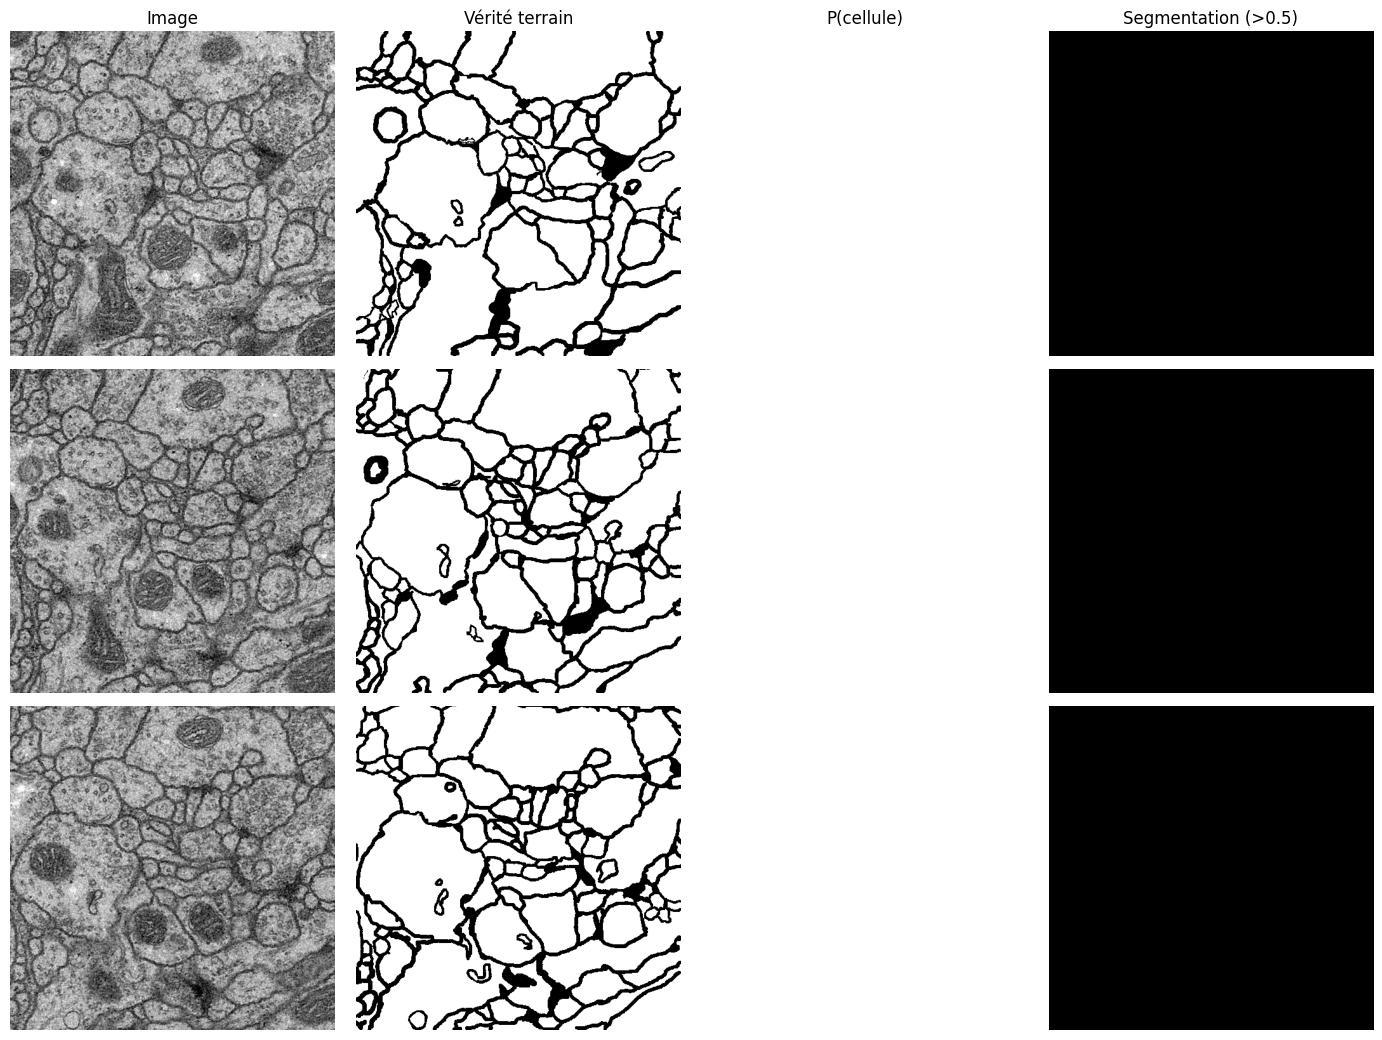

{'pixel_acc': 0.19899215698242187, 'dice': 0.0, 'iou': 0.0}


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot([h[0] for h in history]); ax[0].set_title("Perte (train)"); ax[0].set_xlabel("époque")
ax[1].plot([h[1] for h in history]); ax[1].set_title("Dice cellule (validation)"); ax[1].set_xlabel("époque")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(3, 4, figsize=(14, 10.5))
for c in range(3):
    prob = predict_full(model, va_img[c])
    ax[c,0].imshow(va_img[c], cmap="gray"); ax[c,1].imshow(va_lab[c], cmap="gray")
    ax[c,2].imshow(prob, cmap="gray"); ax[c,3].imshow(prob > 0.5, cmap="gray")
    for a in ax[c]: a.axis("off")
for a, t in zip(ax[0], ["Image", "Vérité terrain", "P(cellule)", "Segmentation (>0.5)"]): a.set_title(t)
plt.tight_layout(); plt.show()
print(evaluate(model))